# 03 AfroXLMR-mini

Three runs of AfroXLMR-mini (Alabi et al., 2022): a frozen probe that trains only the classification head, a full fine-tune, and a full fine-tune with inverse-frequency class weights. Each run keeps the epoch with the best development macro-F1.

Training takes about 20 minutes per fine-tune on a laptop GPU and a few minutes on a Colab T4 (Runtime, Change runtime type, T4 GPU). With `RETRAIN = False` the notebook only shows the saved runs from `results/*_train.json`; the checkpoints themselves (about 465 MB each) are not in the repository.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Keaane/Ikinyamakuru/blob/main/notebooks/03_afroxlmr.ipynb)

In [1]:
# Setup: run from the repository root, on a laptop or on Colab.
import os
import subprocess
import sys
import warnings
from pathlib import Path

if "google.colab" in sys.modules:
    if not Path("/content/Ikinyamakuru").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/Keaane/Ikinyamakuru.git", "/content/Ikinyamakuru"], check=True)
    os.chdir("/content/Ikinyamakuru")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
elif Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, str(Path("src").resolve()))

# Show each warning as one short line.
warnings.showwarning = lambda message, category, *args, **kwargs: print(f"{category.__name__}: {message}")

In [2]:
RETRAIN = False  # True trains all three runs again and overwrites models/runs/ and their results

In [3]:
import json

import matplotlib.pyplot as plt
import numpy as np

from inkuru.data import load_split, records, write_jsonl
from inkuru.labels import LABELS
from inkuru.metrics import classification_scores
from inkuru.paths import MAX_LENGTH, MODEL_NAME, RESULTS, RUNS, SEED

## Training

The encoder learning rate is 2e-5 and the head learning rate 1e-3 (the probe trains the head only, at 1e-3). AdamW uses weight decay 0.01 except on biases and layer-norm scales, gradients are clipped at 1.0, and each run lasts three epochs at batch size 8 on the first 128 subword tokens of each article.

In [4]:
def apply_mode(model, mode: str) -> None:
    for param in model.parameters():
        param.requires_grad = mode == "full"
    if mode == "probe":
        for param in model.classifier.parameters():
            param.requires_grad = True


def train_mode(model, mode: str) -> None:
    model.train()
    if mode == "probe":
        model.roberta.eval()  # the frozen encoder keeps its dropout off


def class_weights(labels: list[int], n_labels: int):
    import torch

    counts = np.bincount(np.asarray(labels), minlength=n_labels).astype(np.float64)
    return torch.tensor(counts.sum() / (n_labels * np.maximum(counts, 1.0)), dtype=torch.float32)


def run(mode: str, class_weight: bool = False, epochs: int = 3, batch: int = 8, lr: float | None = None) -> dict:
    import torch
    from torch.utils.data import DataLoader
    from transformers import AutoModelForSequenceClassification, AutoTokenizer

    from inkuru.encoder import TextSet, collate, device_of, predict, set_seed

    name = mode + ("_weighted" if class_weight else "")
    lr = lr if lr is not None else (1e-3 if mode == "probe" else 2e-5)
    set_seed(SEED)
    device = device_of()
    print(f"{name} device={device} lr={lr} max_length={MAX_LENGTH}")

    train_rows, dev_rows = load_split("train"), load_split("dev")
    label_index = {label: index for index, label in enumerate(LABELS)}
    train_y = [label_index[row["label"]] for row in train_rows]
    dev_y = [label_index[row["label"]] for row in dev_rows]

    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=len(LABELS),
        id2label={index: label for index, label in enumerate(LABELS)}, label2id=label_index,
    )
    apply_mode(model, mode)
    model.to(device)
    train_loader = DataLoader(TextSet([row["text"] for row in train_rows], train_y), batch_size=batch,
                              shuffle=True, collate_fn=lambda b: collate(tokenizer, b))
    dev_loader = DataLoader(TextSet([row["text"] for row in dev_rows], dev_y), batch_size=16,
                            shuffle=False, collate_fn=lambda b: collate(tokenizer, b))

    encoder_lr = lr if mode == "full" else 0.0
    head_lr = 1e-3 if mode == "full" else lr
    decay, plain, head_decay, head_plain = [], [], [], []
    for param_name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        no_wd = param_name.endswith("bias") or "LayerNorm" in param_name or "layer_norm" in param_name
        if param_name.startswith("classifier."):
            (head_plain if no_wd else head_decay).append(param)
        else:
            (plain if no_wd else decay).append(param)
    groups = []
    for params, group_lr, wd in ((decay, encoder_lr, 0.01), (plain, encoder_lr, 0.0),
                                 (head_decay, head_lr, 0.01), (head_plain, head_lr, 0.0)):
        if params:
            groups.append({"params": params, "lr": group_lr, "weight_decay": wd})
    optimizer = torch.optim.AdamW(groups)
    weights = class_weights(train_y, len(LABELS)).to(device) if class_weight else None
    criterion = torch.nn.CrossEntropyLoss(weight=weights)

    best_f1, best_state, best_epoch, history = -1.0, None, -1, []
    for epoch in range(epochs):
        train_mode(model, mode)
        total, seen = 0.0, 0
        for step, batch_inputs in enumerate(train_loader, start=1):
            labels = batch_inputs.pop("labels").to(device)
            batch_inputs = {key: value.to(device) for key, value in batch_inputs.items()}
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(**batch_inputs).logits, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total += float(loss.item()) * labels.size(0)
            seen += labels.size(0)
            if step % 200 == 0:
                print(f"   epoch {epoch} step {step} loss {total / max(seen, 1):.4f}")
        proba, gold_index = predict(model, dev_loader, device)
        scores = classification_scores([LABELS[int(i)] for i in gold_index], [LABELS[int(i)] for i in proba.argmax(axis=1)])
        row = {"epoch": epoch, "loss": total / max(seen, 1), "dev_macro_f1": scores["macro_f1"], "dev_accuracy": scores["accuracy"]}
        history.append(row)
        print(f"epoch {epoch} loss {row['loss']:.4f} development macro-F1 {row['dev_macro_f1']:.4f} accuracy {row['dev_accuracy']:.4f}")
        if scores["macro_f1"] > best_f1:
            best_f1, best_epoch = scores["macro_f1"], epoch
            best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}

    model.load_state_dict(best_state)
    out = RUNS / name
    out.mkdir(parents=True, exist_ok=True)
    model.save_pretrained(out)
    tokenizer.save_pretrained(out)
    proba, _ = predict(model, dev_loader, device)
    write_jsonl(RESULTS / f"{name}_dev.jsonl", records(dev_rows, proba))
    meta = {"name": name, "mode": mode, "class_weight": class_weight, "lr": lr, "head_lr": head_lr,
            "max_length": MAX_LENGTH, "best_epoch": best_epoch, "best_dev_macro_f1": best_f1,
            "history": history, "model": MODEL_NAME}
    (out / "run.json").write_text(json.dumps(meta, indent=2) + "\n")
    (RESULTS / f"{name}_train.json").write_text(json.dumps(meta, indent=2) + "\n")
    print(f"saved {name}: epoch {best_epoch}, development macro-F1 {best_f1:.4f}")
    return meta

In [5]:
if RETRAIN:
    run("probe")

In [6]:
if RETRAIN:
    run("full")

In [7]:
if RETRAIN:
    run("full", class_weight=True)

## The three runs

Development scores per epoch, from `results/*_train.json`. In all three runs the best epoch is the last one.

probe: best epoch 2, development macro-F1 0.2395
   epoch 0  loss 1.8685  development macro-F1 0.2072  accuracy 0.4653
   epoch 1  loss 1.5425  development macro-F1 0.2295  accuracy 0.4902
   epoch 2  loss 1.4333  development macro-F1 0.2395  accuracy 0.5085
full: best epoch 2, development macro-F1 0.4769
   epoch 0  loss 1.4683  development macro-F1 0.3834  accuracy 0.6383
   epoch 1  loss 1.0402  development macro-F1 0.4522  accuracy 0.6841
   epoch 2  loss 0.8778  development macro-F1 0.4769  accuracy 0.6999
full_weighted: best epoch 2, development macro-F1 0.4881
   epoch 0  loss 2.0308  development macro-F1 0.4066  accuracy 0.5937
   epoch 1  loss 1.4437  development macro-F1 0.4733  accuracy 0.6750
   epoch 2  loss 1.1776  development macro-F1 0.4881  accuracy 0.6946


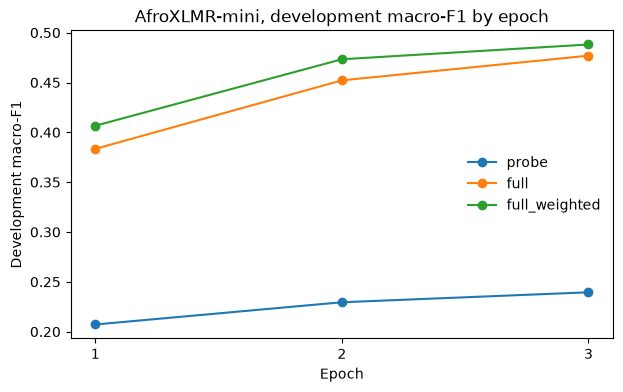

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
for name in ("probe", "full", "full_weighted"):
    info = json.loads((RESULTS / f"{name}_train.json").read_text())
    print(f"{name}: best epoch {info['best_epoch']}, development macro-F1 {info['best_dev_macro_f1']:.4f}")
    for row in info["history"]:
        print(f"   epoch {row['epoch']}  loss {row['loss']:.4f}  development macro-F1 {row['dev_macro_f1']:.4f}  accuracy {row['dev_accuracy']:.4f}")
    ax.plot([row["epoch"] + 1 for row in info["history"]], [row["dev_macro_f1"] for row in info["history"]], marker="o", label=name)
ax.set_xlabel("Epoch")
ax.set_ylabel("Development macro-F1")
ax.set_xticks([1, 2, 3])
ax.set_title("AfroXLMR-mini, development macro-F1 by epoch")
ax.legend(frameon=False)
plt.show()